<a href="https://colab.research.google.com/github/RimeeAwasthi01/Ankuram/blob/main/KNN_Comprehensive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbours



### What this notebook covers

1. Background: what KNN is and the intuition behind it
2. The algorithm and the formulas it uses
3. KNN written from scratch using only NumPy
4. KNN using scikit-learn, and a check that both give the same answer
5. How to pick a good value of K
6. Effect of different distance metrics
7. Why feature scaling matters (with a small experiment)
8. Weighted KNN and KNN for regression
9. A slightly more realistic example (breast cancer dataset)
10. Advantages, limitations and conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
np.random.seed(42)
plt.rcParams['figure.figsize'] = (7, 5)
print("Libraries loaded")

Libraries loaded


## 1. Background

KNN is one of the most intuitive machine learning algorithms out there. The core idea is based on a concept we use in real life: guessing something based on its surroundings. To predict the label of a new data point, KNN looks at the **K points in the training data that are closest to it** and lets them "vote."

Key things to know about KNN:
- It is a **supervised** learning algorithm (we need labeled data).
- It works for both **classification** (predicting a category) and **regression** (predicting a number).
- It is **non-parametric**: it doesn't assume the data follows any specific distribution (like a bell curve).
- It is a **lazy learner**. There is no real "training" phase. The model just memorizes the training data, and all the heavy lifting happens when it's time to make a prediction.

## 2. The Algorithm

Here is how the algorithm processes a new query point $x_q$:
1. Choose the number of neighbors $K$.
2. Calculate the distance between $x_q$ and every single point in the training set.
3. Sort those distances and pick the $K$ closest ones.
4. **For Classification:** Take a majority vote among those $K$ neighbors.
   **For Regression:** Take the average of their target values.

### Distance Metrics

How do we measure "closeness"? For two data points $a$ and $b$ with $d$ features, these are the most common formulas:

**Euclidean distance** (straight-line distance, the default)
$$d(a,b) = \sqrt{\sum_{j=1}^{d} (a_j - b_j)^2}$$

**Manhattan distance** (like navigating a grid of city blocks)
$$d(a,b) = \sum_{j=1}^{d} |a_j - b_j|$$

### Prediction Math (Classification)
The mathematical rule for taking a majority vote looks like this:
$$\hat{y} = \underset{c}{\arg\max} \sum_{x_i \in N_K(x_q)} \mathbb{1}(y_i = c)$$


## 3. The Dataset (Iris)

For our first experiment, we'll use the classic **Iris dataset**. It contains 150 flowers from 3 different species (setosa, versicolor, and virginica), with 4 measurements each: sepal length, sepal width, petal length, and petal width.

In [2]:
# Load the dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print(f"Shape of X: {X.shape}")
print(f"Classes: {list(iris.target_names)}")

Shape of X: (150, 4)
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
display(X.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


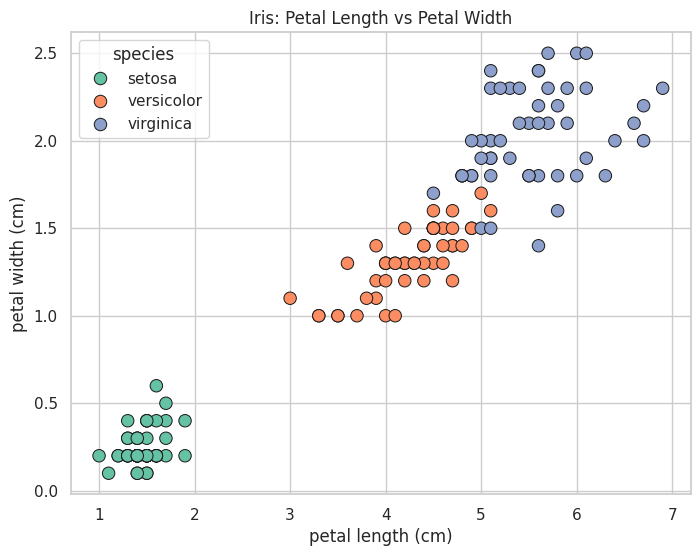

In [4]:
# Let's combine X and y temporarily just for a nice seaborn plot
iris_df = X.copy()
iris_df['species'] = [iris.target_names[val] for val in y]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=iris_df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    palette='Set2',
    edgecolor='k',
    s=80
)
plt.title("Iris: Petal Length vs Petal Width")
plt.show()

Looking at the plot, *setosa* is completely separated from the others. However, *versicolor* and *virginica* overlap a bit in the middle. That overlapping boundary is exactly where our KNN model will have to work hard to make the right predictions!

Next, we need to split our data into a training set (to give to our algorithm) and a testing set (to evaluate how well it learned).

In [5]:
# Split 80% for training and 20% for testing
# stratify=y ensures we get an equal proportion of all 3 flower types in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=42, stratify=y
)

In [6]:
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 120
Testing samples: 30


## 4. KNN from Scratch

Before we rely on scikit-learn, let's write the KNN algorithm from scratch using just NumPy. We will directly follow the 4 mathematical steps we outlined in the Algorithm section.

In [7]:
# straight-line distance
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

# Predict the class for a single new data point
def knn_predict_one(x_query, X_train, y_train, k=5):
    # Step 1: calculate distance from the query point to EVERY training point
    distances = [euclidean(x_query, x) for x in X_train]

    # Step 2: find the indices of the 'k' smallest distances
    nearest_idx = np.argsort(distances)[:k]

    # Step 3: look up the actual labels of those closest neighbors
    nearest_labels = y_train[nearest_idx]

    # Step 4: take a majority vote and return the most common label
    return Counter(nearest_labels).most_common(1)[0][0]

# Apply the single prediction function to an entire dataset
def knn_predict(X_query, X_train, y_train, k=5):
    return np.array([knn_predict_one(x, X_train, y_train, k) for x in X_query])

In [8]:
# Testing our algorithm
y_pred_scratch = knn_predict(X_test, X_train, y_train, k=5)
print(f"Accuracy of scratch KNN (k=5): {accuracy_score(y_test, y_pred_scratch):.4f}")

Accuracy of scratch KNN (k=5): 1.0000


### Following one prediction step-by-step

Let's look under the hood and see exactly how our algorithm "thinks" when predicting the very first flower in our test set.

In [9]:
# Grab the very first flower in our test set
x_new = X_test[0]
actual_label = iris.target_names[y_test[0]]
print(f"Query point measurements: {x_new} | Actual true class: {actual_label}\n")

# Calculate all distances and find the top 5
dists = np.array([euclidean(x_new, x) for x in X_train])
nn = np.argsort(dists)[:5]

# Putting results in a pandas table
result = pd.DataFrame({
    "train_index": nn,
    "distance": dists[nn].round(3),
    "neighbor_class": [iris.target_names[c] for c in y_train[nn]]
})
display(result)

predicted_label = iris.target_names[Counter(y_train[nn]).most_common(1)[0][0]]
print(f"\nMajority vote - {predicted_label}")

Query point measurements: [4.4 3.  1.3 0.2] | Actual true class: setosa



,train_index,distance,neighbor_class
0,0,0.141,setosa
1,93,0.245,setosa
2,119,0.300,setosa
3,58,0.300,setosa
4,116,0.361,setosa



Majority vote - setosa


## 5. KNN with scikit-learn

Now we will use `scikit-learn`'s built-in `KNeighborsClassifier`. We will also verify that our handcrafted model from the previous step gives the exact same predictions as this professional library.

In [10]:
# Initialize and train the scikit-learn model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [11]:
y_pred = knn.predict(X_test)

In [12]:
print(f"Accuracy (sklearn): {accuracy_score(y_test, y_pred):.4f}")
print(f"Did our scratch version get the exact same answers? {np.array_equal(y_pred, y_pred_scratch)}")

Accuracy (sklearn): 1.0000
Did our scratch version get the exact same answers? True


In [13]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



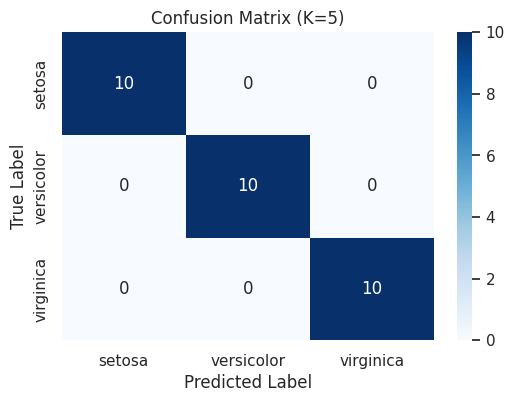

In [14]:
# Create a confusion matrix using Seaborn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title("Confusion Matrix (K=5)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## 6. Choosing the right value of K

K is the main "hyperparameter" of KNN, and it controls the bias-variance trade-off:
- **Small K (e.g., K=1):** The model trusts the closest single neighbor completely. It captures a lot of noise and is prone to **overfitting** (low bias, high variance).
- **Large K:** The model takes a massive vote, smoothing over local details. It can become too simple and is prone to **underfitting** (high bias, low variance).

A single train/test split can be misleading, so we will use **5-fold cross-validation** to try a range of K values and find the best one.

In [15]:
k_values = range(1, 31)
cv_scores = []
train_scores = []

# Try every K from 1 to 30
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    # Calculating cross-validation score
    cv_scores.append(cross_val_score(model, X_train, y_train, cv=5).mean())
    # Calculating training score just to see overfitting in action
    train_scores.append(model.fit(X_train, y_train).score(X_train, y_train))

best_k = k_values[int(np.argmax(cv_scores))]

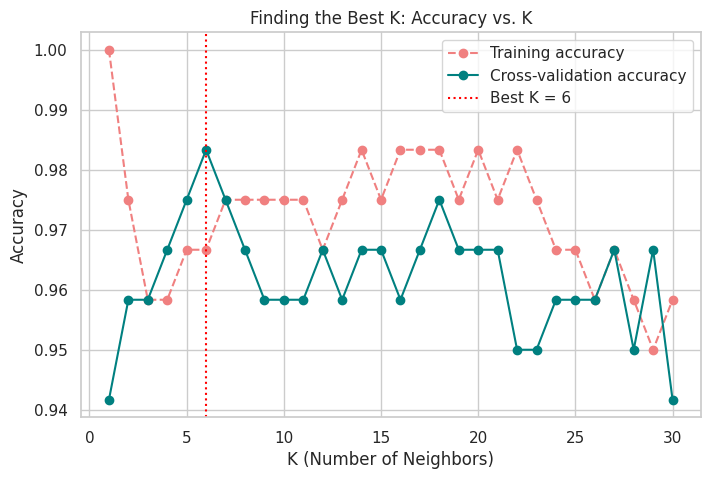

Best K from cross-validation: 6 | CV Accuracy: 0.9833


In [16]:
# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(k_values, train_scores, 'o--', label='Training accuracy', color='lightcoral')
plt.plot(k_values, cv_scores, 'o-', label='Cross-validation accuracy', color='teal')
plt.axvline(best_k, color='red', linestyle=':', label=f'Best K = {best_k}')

plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("Finding the Best K: Accuracy vs. K")
plt.legend()
plt.show()

print(f"Best K from cross-validation: {best_k} | CV Accuracy: {max(cv_scores):.4f}")

## 7. Visualizing Decision Boundaries

To truly understand how K affects our model, let's visualize the "territories" or decision boundaries it creates. We will use just two features so we can plot them on a 2D graph. Look at how the boundaries change from jagged (overfitting) to overly smooth (underfitting) as K increases.

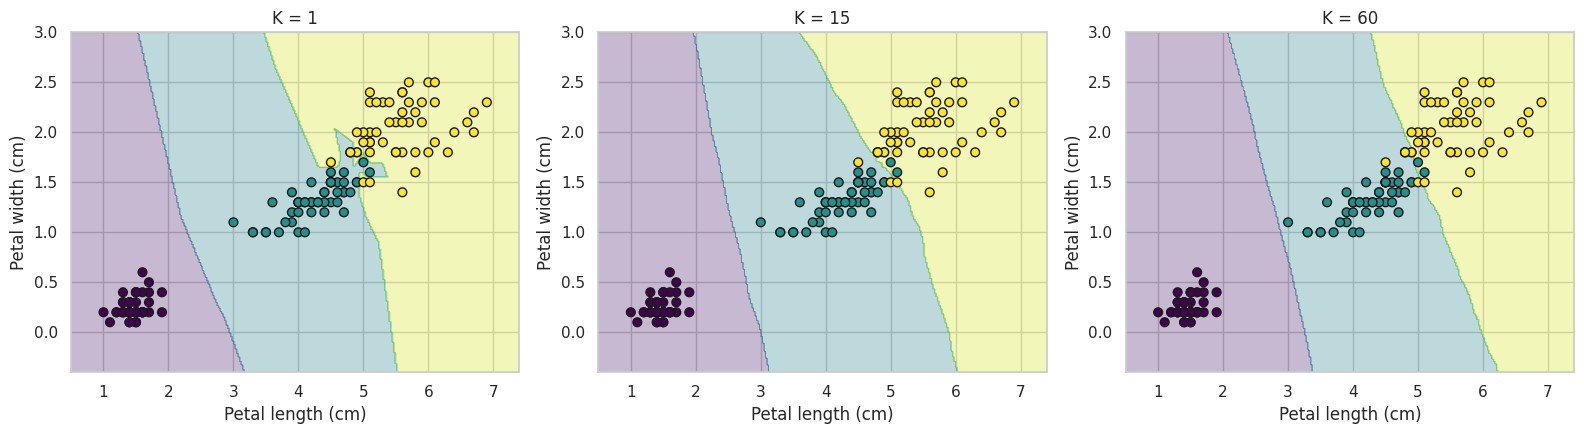

In [17]:
# Grab just petal length and width for 2D plotting
X2 = X.iloc[:, 2:4].values
y_vals = y.values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Create a grid of points to predict across the entire plot
x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

# Try 3 very different K values to see the contrast
for ax, k in zip(axes, [1, 15, 60]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X2, y_vals)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Fill the background regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    # Plot the actual flower data points on top
    ax.scatter(X2[:, 0], X2[:, 1], c=y_vals, edgecolor='k', cmap='viridis', s=40)

    ax.set_title(f"K = {k}")
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")

plt.tight_layout()
plt.show()

## 8. Effect of the Distance Metric

We've been using Euclidean distance by default. Let's see if swapping to Manhattan or Chebyshev distance changes our model's performance on the Iris dataset.

In [18]:
metrics = ['euclidean', 'manhattan', 'chebyshev']

print("Cross-Validation Accuracy by Distance Metric:\n")
for metric in metrics:
    # using best_k we calculated dynamically earlier
    m = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    score = cross_val_score(m, X_train, y_train, cv=5).mean()
    print(f"{metric.capitalize():10s} - Accuracy: {score:.4f}")

Cross-Validation Accuracy by Distance Metric:

Euclidean  - Accuracy: 0.9833
Manhattan  - Accuracy: 0.9583
Chebyshev  - Accuracy: 0.9667


## 9. Why Feature Scaling Matters

KNN is highly sensitive to the magnitude of features. If we don't scale our data, features with larger numeric ranges will artificially overpower features with smaller ranges during the distance calculation.

To demonstrate this, we will use the **Breast Cancer Dataset** (predicting if a tumor is malignant or benign based on 30 cellular features). First, let's look at how wildly different the feature ranges are.

In [19]:
# Load the breast cancer dataset
cancer = load_breast_cancer(as_frame=True)
Xc = cancer.data
yc = cancer.target

In [20]:
print(f"Dataset Shape: {Xc.shape} , Classes: {list(cancer.target_names)}")

Dataset Shape: (569, 30) , Classes: [np.str_('malignant'), np.str_('benign')]


In [21]:
# Calculate the range for every single feature
ranges = (Xc.max() - Xc.min()).sort_values(ascending=False)

print("\nLargest feature ranges (will dominate distance math):")
print(ranges.head(3).round(2))

print("\nSmallest feature ranges (will be ignored):")
print(ranges.tail(3).round(4))


Largest feature ranges (will dominate distance math):
worst area    4068.8
mean area     2357.5
area error     535.4
dtype: float64

Smallest feature ranges (will be ignored):
mean fractal dimension     0.0475
smoothness error           0.0294
fractal dimension error    0.0289
dtype: float64


In [22]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

# Model 1: WITHOUT scaling
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(Xc_train, yc_train)
acc_raw = knn_raw.score(Xc_test, yc_test)

# Model 2: WITH scaling
# We use a pipeline to ensure the scaler only learns from the training data, preventing data leakage!
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xc_train, yc_train)
acc_scaled = knn_scaled.score(Xc_test, yc_test)

In [23]:
print(f"Accuracy WITHOUT scaling: {acc_raw:.4f}")
print(f"Accuracy WITH scaling   : {acc_scaled:.4f}")

Accuracy WITHOUT scaling: 0.9123
Accuracy WITH scaling   : 0.9561


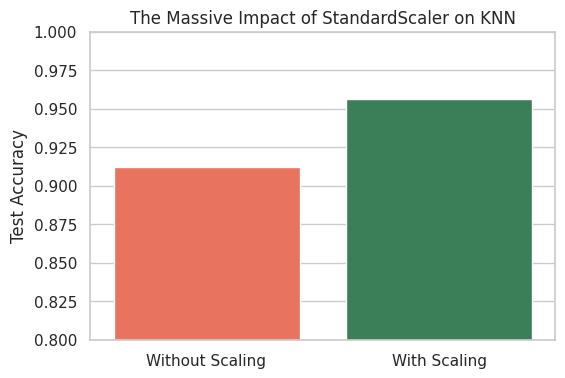

In [24]:
# Plot the difference (Updated for newer Seaborn versions)
plt.figure(figsize=(6, 4))
sns.barplot(
    x=['Without Scaling', 'With Scaling'],
    y=[acc_raw, acc_scaled],
    hue=['Without Scaling', 'With Scaling'], # Added hue to fix the warning
    palette=['tomato', 'seagreen'],
    legend=False # Hide the redundant legend
)
plt.ylim(0.8, 1.0)
plt.ylabel("Test Accuracy")
plt.title("The Massive Impact of StandardScaler on KNN")
plt.show()

Standardization transforms each feature using this formula:
$$z = \frac{x - \mu}{\sigma}$$
This forces every feature to have a mean ($\mu$) of 0 and a standard deviation ($\sigma$) of 1.

**Important:** Always scale features before using KNN or any other distance-based algorithm. Furthermore, always fit scaler on the training data only to avoid data leakage.

## 10. Uniform vs. Distance-Weighted Voting

In standard KNN, voting is uniform. However, we can use **distance-weighted voting**, where a neighbor's vote is weighted inversely to its distance ($weight = 1/distance$). This means closer neighbors get a louder voice in the final decision.

Let's test this on our breast cancer dataset using scikit-learn's `weights='distance'` parameter.

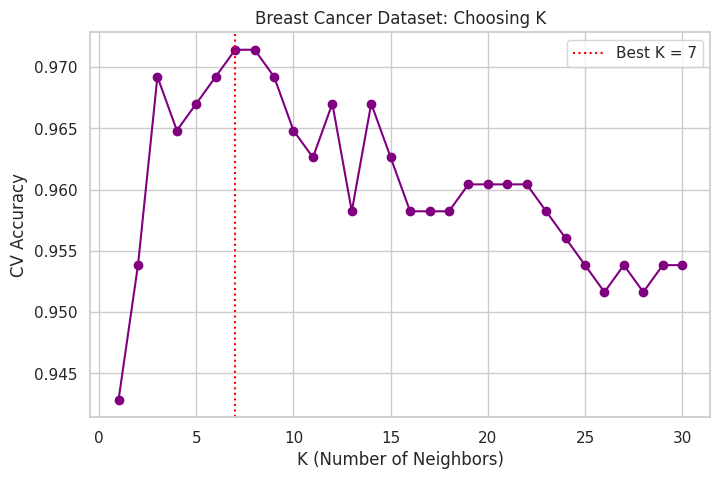

Best K = 7 | Final Test Accuracy = 0.9737

              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [25]:
ks = range(1, 31)
scores = []

# Find the best K using cross-validation
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores.append(cross_val_score(pipe, Xc_train, yc_train, cv=5).mean())

best_k_c = ks[int(np.argmax(scores))]

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(ks, scores, 'o-', color='purple')
plt.axvline(best_k_c, color='red', linestyle=':', label=f'Best K = {best_k_c}')
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("CV Accuracy")
plt.title("Breast Cancer Dataset: Choosing K")
plt.legend()
plt.show()

# Train the final optimized model
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k_c)).fit(Xc_train, yc_train)
pred = final_model.predict(Xc_test)

print(f"Best K = {best_k_c} | Final Test Accuracy = {accuracy_score(yc_test, pred):.4f}\n")
print(classification_report(yc_test, pred, target_names=cancer.target_names))

## 12. KNN for Regression

KNN isn't just for classification; it can also predict continuous numbers. Instead of taking a vote, `KNeighborsRegressor` calculates the average of the target values of the K nearest neighbors.

To see this in action, let's generate a noisy sine wave and see how different values of K attempt to fit a line through the data.

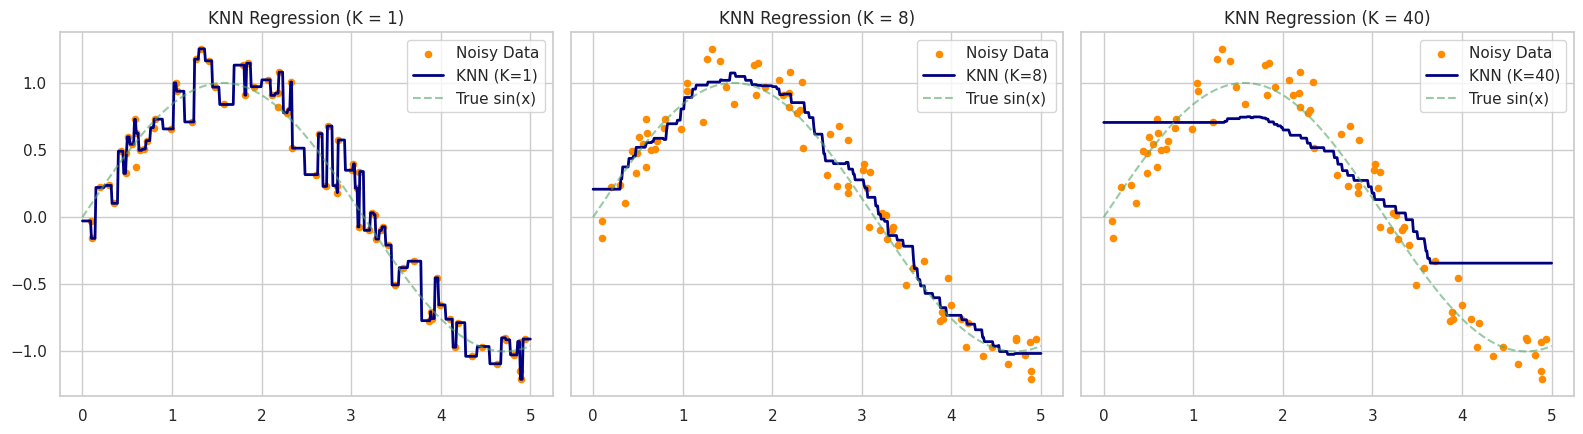

In [26]:
# Generate noisy sine wave data
rng = np.random.RandomState(0)
Xr = np.sort(5 * rng.rand(80, 1), axis=0)
yr = np.sin(Xr).ravel() + rng.normal(0, 0.15, 80)
X_line = np.linspace(0, 5, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

# Test 3 different K values
for ax, k in zip(axes, [1, 8, 40]):
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr, yr)

    ax.scatter(Xr, yr, color='darkorange', s=20, label='Noisy Data')
    ax.plot(X_line, reg.predict(X_line), color='navy', linewidth=2, label=f'KNN (K={k})')
    ax.plot(X_line, np.sin(X_line), 'g--', alpha=0.6, label='True sin(x)')

    ax.set_title(f"KNN Regression (K = {k})")
    ax.legend()

plt.tight_layout()
plt.show()

## 13. The Curse of Dimensionality

KNN works wonderfully when you have a small number of features. However, as the number of dimensions (features) grows, the math starts to break down.

In high-dimensional space, data points become so spread out that the distance to your "nearest" neighbor becomes almost identical to the distance to your "farthest" neighbor. The concept of "closeness" completely loses its meaning.

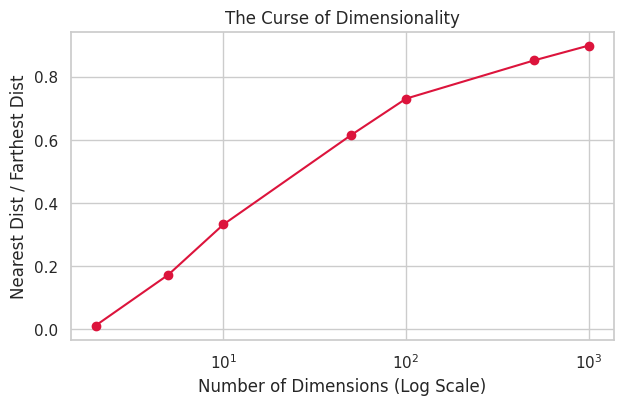

In [27]:
rng = np.random.RandomState(1)
dims = [2, 5, 10, 50, 100, 500, 1000]
ratios = []

# Calculate the ratio of nearest distance to farthest distance in increasing dimensions
for d in dims:
    pts = rng.rand(500, d)
    q = rng.rand(1, d)
    dist = np.sqrt(((pts - q) ** 2).sum(axis=1))
    ratios.append(dist.min() / dist.max())

plt.figure(figsize=(7, 4))
plt.plot(dims, ratios, 'o-', color='crimson')
plt.xscale('log')
plt.xlabel("Number of Dimensions (Log Scale)")
plt.ylabel("Nearest Dist / Farthest Dist")
plt.title("The Curse of Dimensionality")
plt.show()

## 14. Advantages, Limitations, and Conclusion

**Advantages:**
- **Simple and Intuitive:** Very easy to understand and explain.
-  **No Training Phase:** As a lazy learner, it simply stores data and adapts immediately when new data is added.
- **Versatile:** Handles both classification (multi-class naturally) and regression.
-  **Non-parametric:** Makes zero assumptions about how the underlying data is distributed.

**Limitations:**
-  **Slow Prediction:** Must calculate the distance to every single training point to make a single prediction.
-  **Memory Heavy:** Requires storing the entire dataset in memory.
-  **Scale Sensitive:** Completely fails if features are not properly scaled.
-  **Curse of Dimensionality:** Performance degrades severely as the number of features increases.

### Final Conclusion
In this notebook, we built KNN from scratch using NumPy and verified it against scikit-learn. We proved that **K controls model complexity** (balancing overfitting vs. underfitting), demonstrated that **feature scaling is absolutely mandatory**, and observed how KNN can easily adapt to both classification and regression tasks. While it may not be the fastest algorithm for massive, high-dimensional datasets, it remains an incredibly powerful baseline model for machine learning.